# Dataset Loading and Treatment

In [35]:
# python imports
import random
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib import patches
from PIL import Image


In [36]:
# Paths
DATASET_PATH = Path("../dataset")
WIDER_TRAIN_DIR = DATASET_PATH / "WIDER_train/images"
WIDER_VAL_DIR = DATASET_PATH / "WIDER_val/images"
WIDER_TEST_DIR = DATASET_PATH / "WIDER_test/images"

# Ficheiros de anotação oficiais
WIDER_TRAIN_ANNO = DATASET_PATH / "wider_face_split/wider_face_train_bbx_gt.txt"
WIDER_VAL_ANNO = DATASET_PATH / "wider_face_split/wider_face_val_bbx_gt.txt"
WIDER_TEST_FILELIST = DATASET_PATH / "wider_face_split/wider_face_test_filelist.txt"

# Ficheiros de teste exteriores
EXT_DATASET_PATH = DATASET_PATH / "test_dataset"
EXT_IMAGES_DIR = EXT_DATASET_PATH / "images"
EXT_LABELS_DIR = EXT_DATASET_PATH / "labels"

# Seed
SEED = 2
random.seed(SEED)

In [37]:
def load_wider_annotations(anno_path: Path, images_dir: Path):
    """
    Carrega as anotações do WIDER FACE e extrai também as dimensões reais da imagem.
    """
    dataset_records = []
    box_records = []
    annotated_images = set()
    
    with open(anno_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]
    
    i = 0
    while i < len(lines):
        img_rel_path = lines[i]
        i += 1
        
        if not img_rel_path.endswith(".jpg"):
            continue
        
        annotated_images.add(img_rel_path)
        num_faces = int(lines[i])
        i += 1
        
        faces_in_image = []
        
        # Obter dimensões reais da imagem no disco para contexto de resolução
        img_path = images_dir / img_rel_path
        img_w, img_h = 0, 0
        if img_path.exists():
            try:
                with Image.open(img_path) as img:
                    img_w, img_h = img.size
            except Exception:
                pass
        
        if num_faces == 0:
            if i < len(lines) and not lines[i].endswith(".jpg"):
                i += 1
        else:
            for _ in range(num_faces):
                parts = list(map(int, lines[i].split()))
                i += 1
                
                if len(parts) >= 9:
                    x, y, w, h = parts[:4]
                    invalid = parts[7]
                    occlusion = parts[8]
                    blur = parts[4] if len(parts) >= 5 else 0
                    
                    if invalid == 0 and w > 0 and h > 0:
                        box_dict = {
                            "x": x, "y": y, "w": w, "h": h,
                            "occlusion": occlusion, "blur": blur,
                            "area": w * h,
                            # Guardar também a proporção face/imagem se útil
                            "relative_w": w / img_w if img_w > 0 else 0,
                            "relative_h": h / img_h if img_h > 0 else 0
                        }
                        faces_in_image.append(box_dict)
                        box_records.append(box_dict)
        
        dataset_records.append({
            "img_rel_path": img_rel_path,
            "boxes": faces_in_image,
            "img_width": img_w,
            "img_height": img_h
        })
    
    return dataset_records, box_records, annotated_images

In [38]:
def load_external_yolo_dataset(labels_dir: Path, images_dir: Path):
    """
    Carrega o dataset externo em formato YOLO e extrai as dimensões reais da imagem.
    """
    dataset_records = []
    box_records = []
    annotated_images = set()
    corrupted = []
    
    txt_files = list(labels_dir.rglob("*.txt"))
    print(f"🔍 Encontrados {len(txt_files)} ficheiros de anotação em {labels_dir}")
    
    for txt_path in txt_files:
        rel_path_from_labels = txt_path.relative_to(labels_dir)
        img_stem = rel_path_from_labels.stem
        
        img_path = images_dir / rel_path_from_labels.parent / f"{img_stem}.jpg"
        if not img_path.exists():
            img_path = images_dir / rel_path_from_labels.parent / f"{img_stem}.png"
            
        if not img_path.exists():
            continue
            
        try:
            with Image.open(img_path) as img:
                img_w, img_h = img.size
        except Exception:
            corrupted.append(str(img_path))
            continue
            
        faces_in_image = []
        dims = []
        
        with open(txt_path, "r") as f:
            lines = f.readlines()
            
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5:
                class_id = int(parts[0])
                if class_id == 0:  # 0 assumido como face
                    x_c = float(parts[1])
                    y_c = float(parts[2])
                    w_norm = float(parts[3])
                    h_norm = float(parts[4])
                    
                    w_abs = int(w_norm * img_w)
                    h_abs = int(h_norm * img_h)
                    x_abs = int((x_c * img_w) - (w_abs / 2))
                    y_abs = int((y_c * img_h) - (h_abs / 2))
                    
                    x_abs = max(0, x_abs)
                    y_abs = max(0, y_abs)
                    w_abs = min(img_w - x_abs, w_abs)
                    h_abs = min(img_h - y_abs, h_abs)
                    
                    if w_abs > 0 and h_abs > 0:
                        box_dict = {
                            "x": x_abs, "y": y_abs, "w": w_abs, "h": h_abs,
                            "occlusion": 0,
                            "blur": 0,
                            "area": w_abs * h_abs,
                            "relative_w": w_abs / img_w if img_w > 0 else 0,
                            "relative_h": h_abs / img_h if img_h > 0 else 0
                        }
                        faces_in_image.append(box_dict)
                        box_records.append(box_dict)
                        dims.append(min(w_abs, h_abs))
        
        img_rel_path = str(rel_path_from_labels.parent / f"{img_stem}.jpg")
        annotated_images.add(img_rel_path)
        
        dataset_records.append({
            "img_rel_path": img_rel_path,
            "boxes": faces_in_image,
            "num_faces": len(faces_in_image),
            "min_dim": min(dims) if dims else 0,
            "max_occlusion": 0,
            "max_blur": 0,
            "img_width": img_w,
            "img_height": img_h
        })

    print(f"\n📁 Dataset Externo (Generalização):")
    print(f"  Imagens processadas: {len(dataset_records)}")
    print(f"  Rostos válidos extraídos: {len(box_records)}")
    
    return dataset_records, box_records, annotated_images

In [39]:
def load_wider_test_filelist(filelist_path, images_dir):
    """
    Carrega a lista de ficheiros do WIDER_test (sem ground truth).
    """
    test_records = []
    
    with open(filelist_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]
    
    for img_rel_path in lines:
        if img_rel_path.endswith(".jpg"):
            test_records.append({"img_rel_path": img_rel_path})
    
    actual_images = {p.relative_to(images_dir).as_posix() 
                     for p in images_dir.rglob("*.jpg")}
    filelist_set = {r["img_rel_path"] for r in test_records}
    
    print(f"📁 Partição TEST: {filelist_path.parent.name}")
    print(f"  Imagens no disco: {len(actual_images)}")
    print(f"  Imagens no filelist: {len(filelist_set)}")
    
    missing = actual_images - filelist_set
    extra = filelist_set - actual_images
    
    if not missing and not extra:
        print(f"  ✅ Filelist coincide com imagens no disco")
    else:
        if missing:
            print(f"  ⚠️ Imagens no disco sem entrada no filelist: {len(missing)}")
        if extra:
            print(f"  ⚠️ Entradas no filelist sem imagem no disco: {len(extra)}")
    
    return test_records

In [40]:
print("=" * 60)
print("A CARREGAR PARTIÇÕES OFICIAIS DO WIDER FACE")
print("=" * 60)

print("\n--- TRAIN ---")
train_records, train_boxes, train_annotated = load_wider_annotations(
    WIDER_TRAIN_ANNO, WIDER_TRAIN_DIR
)

print("\n--- VAL ---")
val_records, val_boxes, val_annotated = load_wider_annotations(
    WIDER_VAL_ANNO, WIDER_VAL_DIR
)

print("\n--- TEST ---")
test_records = load_wider_test_filelist(WIDER_TEST_FILELIST, WIDER_TEST_DIR)

A CARREGAR PARTIÇÕES OFICIAIS DO WIDER FACE

--- TRAIN ---

--- VAL ---

--- TEST ---
📁 Partição TEST: wider_face_split
  Imagens no disco: 16097
  Imagens no filelist: 16097
  ✅ Filelist coincide com imagens no disco


In [41]:
print("="*60)
print("A CARREGAR DATASET EXTERNO PARA TESTE DE GENERALIZAÇÃO")
print("="*60)

# 1. Carregar separadamente para ver estatísticas, ou direto em conjunto
# Vamos carregar tudo de uma vez, pois a função usa rglob("*.txt") que pega em train e val
ext_records, ext_boxes, ext_annotated = load_external_yolo_dataset(EXT_LABELS_DIR, EXT_IMAGES_DIR)

# Opcional: Filtrar apenas imagens que têm pelo menos 1 rosto (tal como fazes no WIDER)
ext_records_filtered = [r for r in ext_records if len(r["boxes"]) > 0]
print(f"Imagens com pelo menos 1 rosto: {len(ext_records_filtered)}")

A CARREGAR DATASET EXTERNO PARA TESTE DE GENERALIZAÇÃO
🔍 Encontrados 16733 ficheiros de anotação em ..\dataset\test_dataset\labels

📁 Dataset Externo (Generalização):
  Imagens processadas: 16733
  Rostos válidos extraídos: 51831
Imagens com pelo menos 1 rosto: 16733


In [42]:
def classify_difficulty(boxes):
    """
    Classifica o nível de dificuldade com base nos critérios oficiais do WIDER FACE:
      - Hard: rostos < 15px, oclusão severa (2), blur severo (2) ou multidões (> 30)
      - Medium: rostos < 40px, oclusão parcial (1), blur ligeiro (1) ou grupos (> 5)
      - Easy: rostos proeminentes (>= 40px), nítidos e desimpedidos
    """
    if not boxes:
        return "Unknown"
    
    min_dim = min(min(b["w"], b["h"]) for b in boxes)
    max_occlusion = max(b["occlusion"] for b in boxes)
    max_blur = max(b["blur"] for b in boxes)
    num_faces = len(boxes)
    
    if min_dim < 15 or max_occlusion == 2 or max_blur == 2 or num_faces > 30:
        return "Hard"
    elif min_dim < 40 or max_occlusion == 1 or max_blur == 1 or num_faces > 5:
        return "Medium"
    else:
        return "Easy"


def build_difficulty_buckets(records):
    """Cria buckets de dificuldade a partir de uma lista de records."""
    difficulty_buckets = {"Easy": [], "Medium": [], "Hard": []}

    for item in records:
        # Considera apenas imagens que contenham pelo menos um rosto válido
        if not item["boxes"]:
            continue

        level = classify_difficulty(item["boxes"])
        if level in difficulty_buckets:
            difficulty_buckets[level].append(item)
        
    return difficulty_buckets

In [43]:
print("\n" + "=" * 60)
print("CLASSIFICAÇÃO POR DIFICULDADE")
print("=" * 60)

train_buckets = build_difficulty_buckets(train_records)
val_buckets = build_difficulty_buckets(val_records)

print("\n📊 TRAIN:")
print(f"  Easy:   {len(train_buckets['Easy']):>5}")
print(f"  Medium: {len(train_buckets['Medium']):>5}")
print(f"  Hard:   {len(train_buckets['Hard']):>5}")
print(f"  Total:  {sum(len(v) for v in train_buckets.values()):>5}")

print("\n📊 VAL:")
print(f"  Easy:   {len(val_buckets['Easy']):>5}")
print(f"  Medium: {len(val_buckets['Medium']):>5}")
print(f"  Hard:   {len(val_buckets['Hard']):>5}")
print(f"  Total:  {sum(len(v) for v in val_buckets.values()):>5}")

print("\n📊 TEST:")
print("  (sem ground truth — não aplicável)")


CLASSIFICAÇÃO POR DIFICULDADE

📊 TRAIN:
  Easy:    4419
  Medium:  2962
  Hard:    5495
  Total:  12876

📊 VAL:
  Easy:    1092
  Medium:   725
  Hard:    1405
  Total:   3222

📊 TEST:
  (sem ground truth — não aplicável)


In [44]:
def plot_dataset_stats(records, boxes, title_prefix):
    """Plota estatísticas de uma partição usando escalas relativas."""
    df_boxes = pd.DataFrame(boxes)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"{title_prefix} — Statistics (Relative Scale)", fontsize=14, weight="bold")
    
    # 1. Dimensões relativas (W vs H normalizados)
    if len(df_boxes) > 0:
        sample_df = df_boxes.sample(min(5000, len(df_boxes)), random_state=SEED)
        sns.scatterplot(data=sample_df, x="relative_w", y="relative_h", alpha=0.3, ax=axes[0])
    axes[0].set_title("Relative Bounding Boxes (W vs H)")
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1)
    axes[0].set_xlabel("Relative Width (W / Img_W)")
    axes[0].set_ylabel("Relative Height (H / Img_H)")
    
    # 2. Distribuição de área
    if len(df_boxes) > 0:
        sns.histplot(df_boxes["area"], bins=50, log_scale=True, ax=axes[1], color="teal")
    axes[1].set_title("Area Distribution (Log Scale)")
    
    # 3. Oclusão
    if len(df_boxes) > 0:
        sns.countplot(data=df_boxes, x="occlusion", ax=axes[2], palette="viridis")
    axes[2].set_title("Occlusion Levels (0: None, 1: Partial, 2: Severe)")
    
    plt.tight_layout()
    plt.show()

def plot_difficulty_samples(buckets, title_prefix, images_dir):
    """Plota amostras de cada nível de dificuldade com suporte a diretórios dinâmicos."""
    samples = []
    for label in ["Easy", "Medium", "Hard"]:
        if buckets[label]:
            samples.append((label, random.choice(buckets[label])))
    
    if not samples:
        print(f"  ⚠️ Sem amostras para {title_prefix}")
        return
    
    colors = {"Easy": "lime", "Medium": "gold", "Hard": "red"}
    fig, axes = plt.subplots(1, len(samples), figsize=(6 * len(samples), 8))
    if len(samples) == 1:
        axes = [axes]
    
    fig.suptitle(f"{title_prefix} — Samples per Difficulty", fontsize=14, weight="bold")
    
    for ax, (label, sample) in zip(axes, samples):
        img_path = images_dir / sample["img_rel_path"]
        
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        
        for b in sample["boxes"]:
            rect = patches.Rectangle(
                (b["x"], b["y"]), b["w"], b["h"],
                linewidth=1.8, edgecolor=colors[label], facecolor="none"
            )
            ax.add_patch(rect)
        
        img_name = sample["img_rel_path"].split("/")[-1]
        ax.set_title(f"{label} | {len(sample['boxes'])} faces | {img_name}", fontsize=11)
        ax.axis("off")
    
    plt.tight_layout()
    plt.show()


def plot_external_stats(records, boxes, title_prefix="Dataset Externo"):
    """Plota estatísticas adaptadas para o dataset externo com escalas relativas."""
    df_boxes = pd.DataFrame(boxes)
    df_faces_per_img = pd.DataFrame([len(item["boxes"]) for item in records if len(item["boxes"]) > 0], 
                                     columns=["faces"])
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"{title_prefix} — Global Stats (Relativa Scale)", fontsize=14, weight="bold")
    
    # 1. Dispersão de Dimensões Relativas
    if len(df_boxes) > 0:
        sample_df = df_boxes.sample(min(5000, len(df_boxes)), random_state=SEED)
        sns.scatterplot(data=sample_df, x="relative_w", y="relative_h", alpha=0.3, ax=axes[0], color="orange")
    axes[0].set_title(" Relative Bounding Boxes (W vs H)")
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1)
    axes[0].set_xlabel("Relative Width (W / Img_W)")
    axes[0].set_ylabel("Relative Height (H / Img_H)")
    
    # 2. Distribuição de Área
    if len(df_boxes) > 0:
        sns.histplot(df_boxes["area"], bins=50, log_scale=True, ax=axes[1], color="teal")
    axes[1].set_title("Area Distribution (Log Scale)")
    
    if len(df_faces_per_img) > 0:
        sns.histplot(df_faces_per_img["faces"], bins=range(1, df_faces_per_img["faces"].max() + 2), 
                     ax=axes[2], color="purple", discrete=True)
    axes[2].set_title("Number of Faces per Image")
    axes[2].set_xlabel("Faces")
    axes[2].set_xlim(0, 30)

    plt.tight_layout()
    plt.show()


📈 ESTATÍSTICAS — TRAIN


C:\Users\User\AppData\Local\Temp\ipykernel_24032\2587104795.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_boxes, x="occlusion", ax=axes[2], palette="viridis")


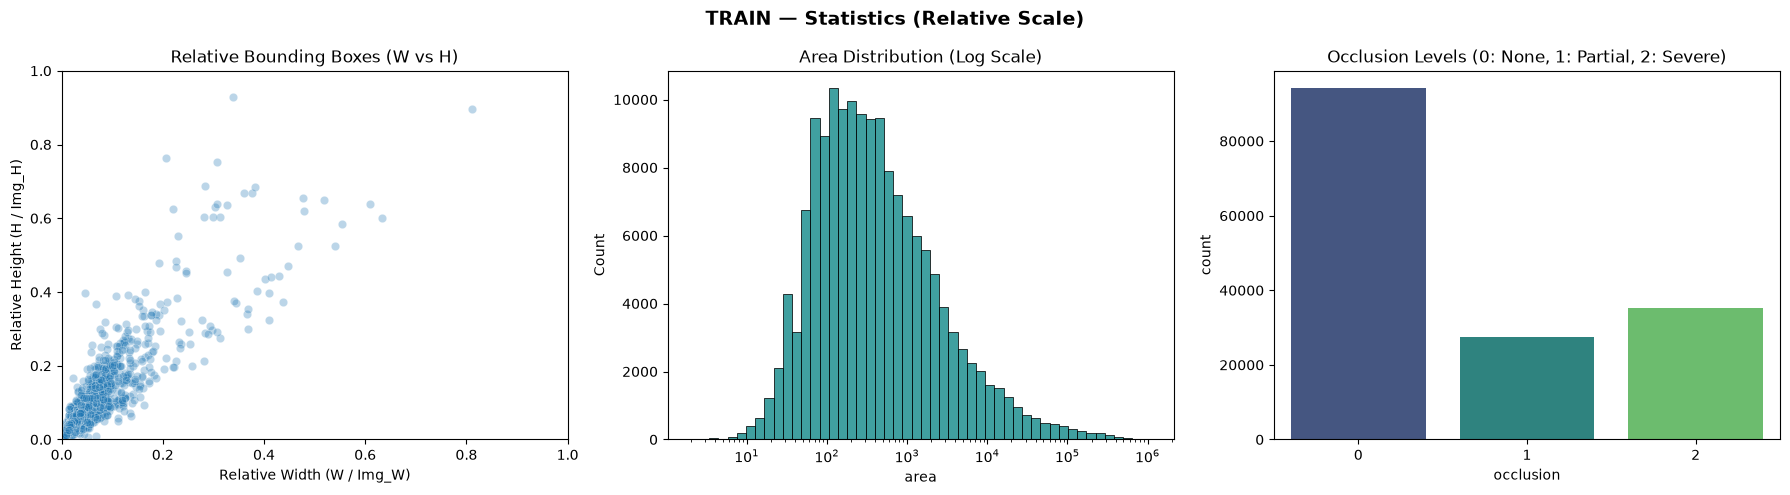


📈 ESTATÍSTICAS — VAL


C:\Users\User\AppData\Local\Temp\ipykernel_24032\2587104795.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_boxes, x="occlusion", ax=axes[2], palette="viridis")


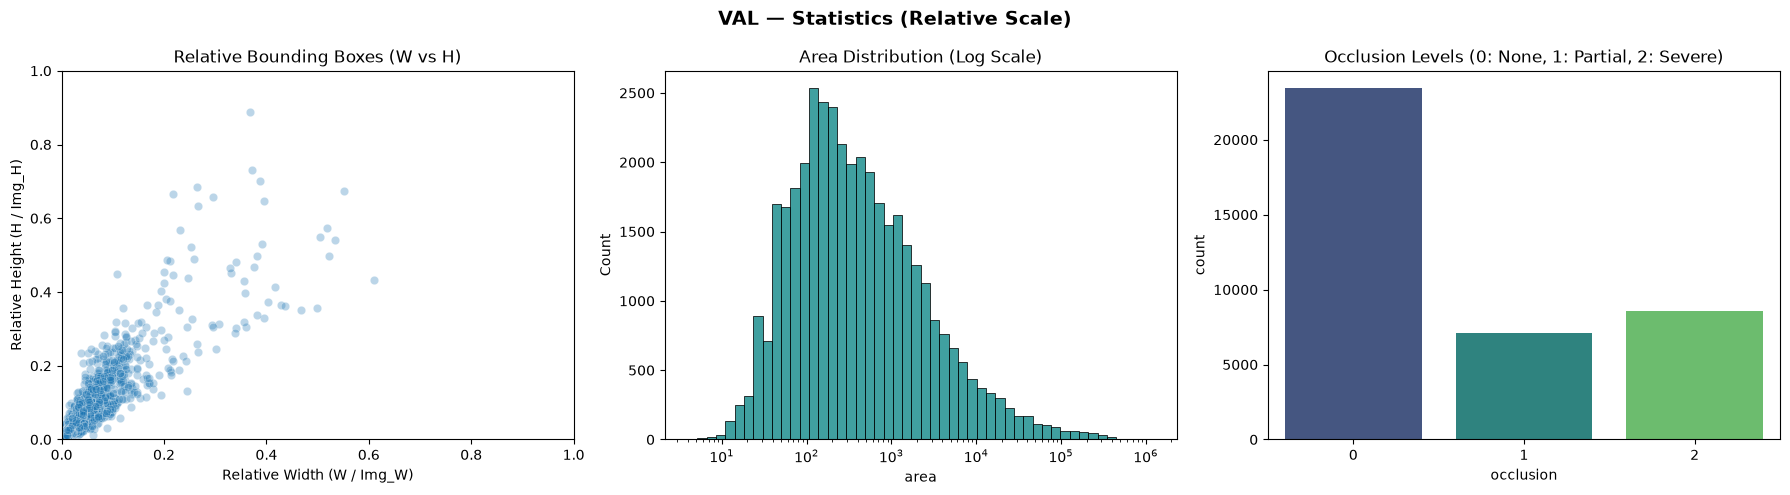


📈 Estatísticas - TEST


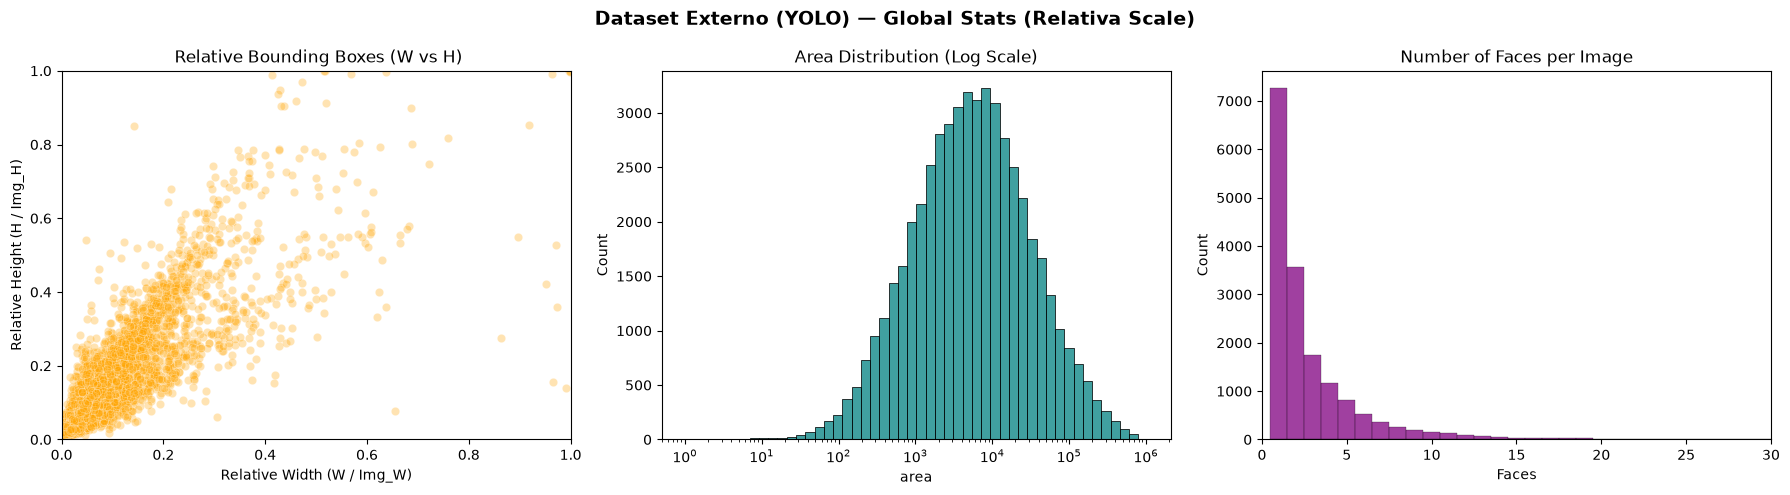


🖼️ AMOSTRAS — TRAIN


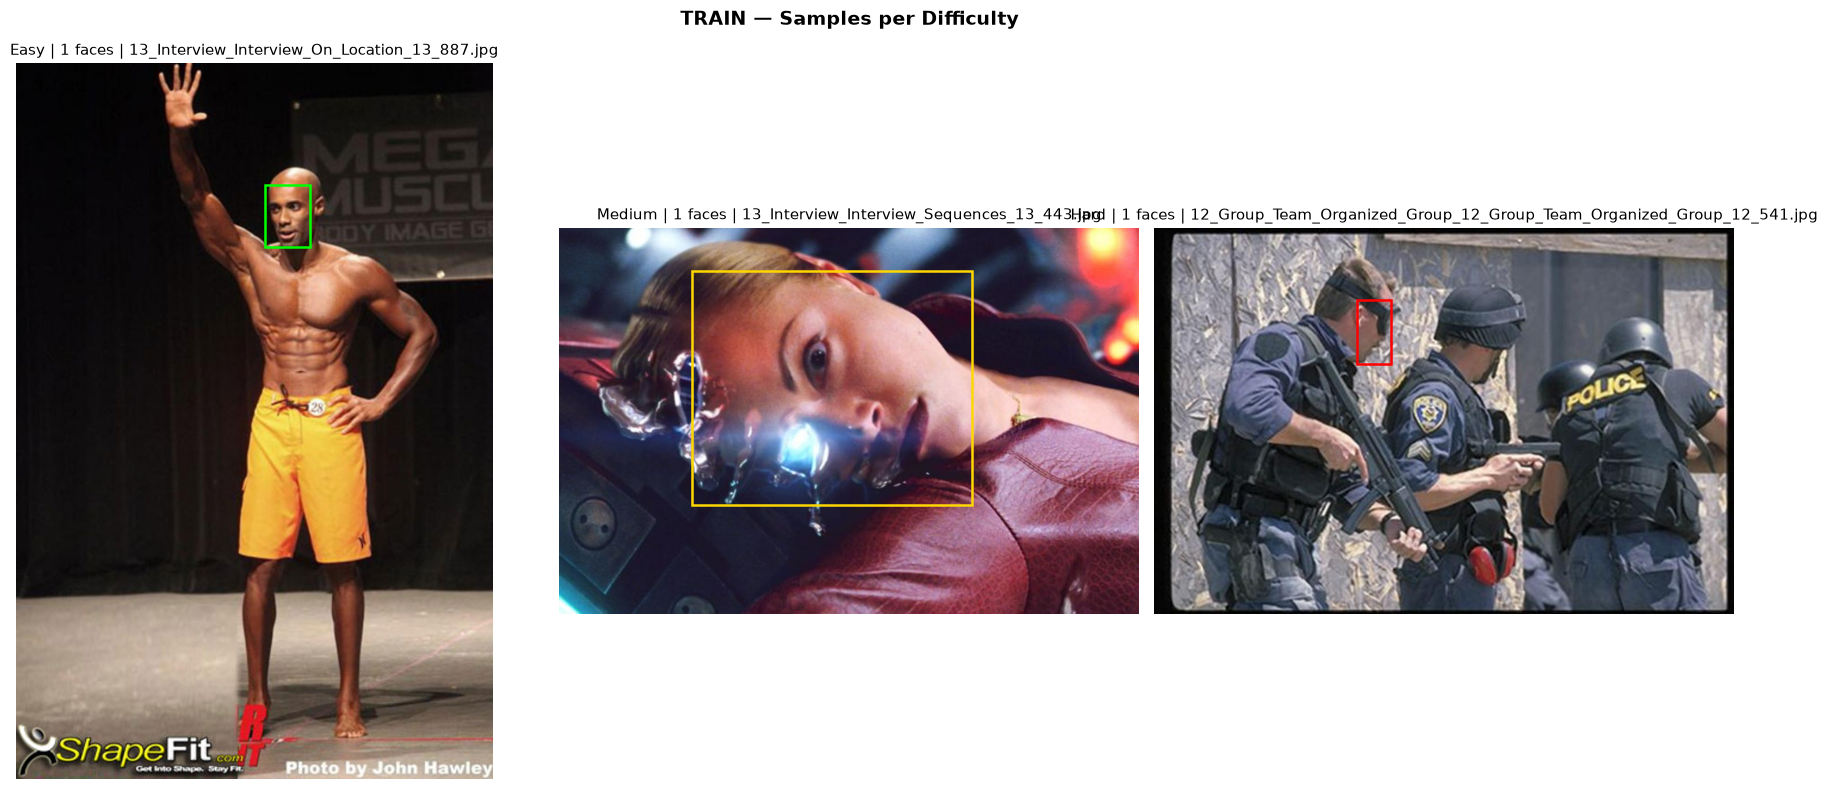


🖼️ AMOSTRAS — VAL


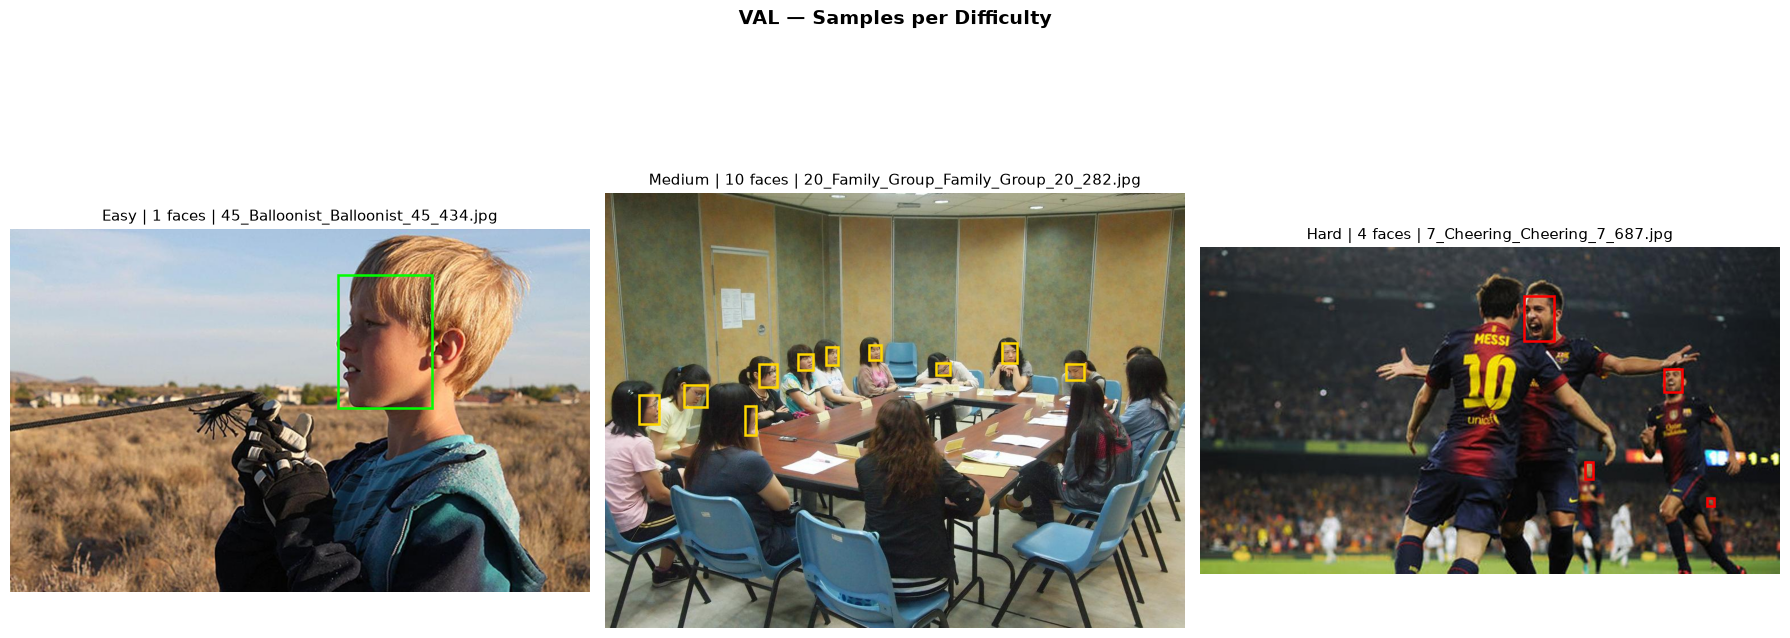


RESUMO DAS PARTIÇÕES OFICIAIS
Partição  Imagens  Rostos Easy Medium Hard
   Train    12880  156994 4419   2962 5495
     Val     3226   39112 1092    725 1405
    Test    16097   51831  N/A    N/A  N/A


In [45]:
print("\n📈 ESTATÍSTICAS — TRAIN")
plot_dataset_stats(train_records, train_boxes, "TRAIN")

print("\n📈 ESTATÍSTICAS — VAL")
plot_dataset_stats(val_records, val_boxes, "VAL")

print("\n📈 Estatísticas - TEST")
plot_external_stats(ext_records_filtered, ext_boxes, "Dataset Externo (YOLO)")

print("\n🖼️ AMOSTRAS — TRAIN")
plot_difficulty_samples(train_buckets, "TRAIN", WIDER_TRAIN_DIR)

print("\n🖼️ AMOSTRAS — VAL")
plot_difficulty_samples(val_buckets, "VAL", WIDER_VAL_DIR)

print("\n" + "=" * 60)
print("RESUMO DAS PARTIÇÕES OFICIAIS")
print("=" * 60)

summary = pd.DataFrame({
    "Partição": ["Train", "Val", "Test"],
    "Imagens": [len(train_records), len(val_records), len(test_records)],
    "Rostos": [len(train_boxes), len(val_boxes), len(ext_boxes)],
    "Easy": [len(train_buckets["Easy"]), len(val_buckets["Easy"]), "N/A"],
    "Medium": [len(train_buckets["Medium"]), len(val_buckets["Medium"]), "N/A"],
    "Hard": [len(train_buckets["Hard"]), len(val_buckets["Hard"]), "N/A"],
})

print(summary.to_string(index=False))

C:\Users\User\AppData\Local\Temp\ipykernel_24032\3912469166.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Dataset")


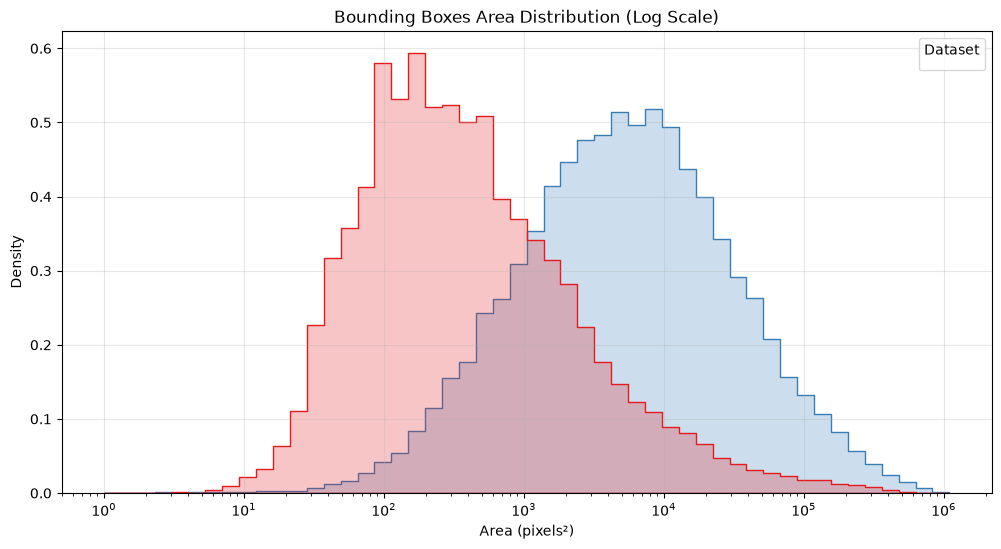

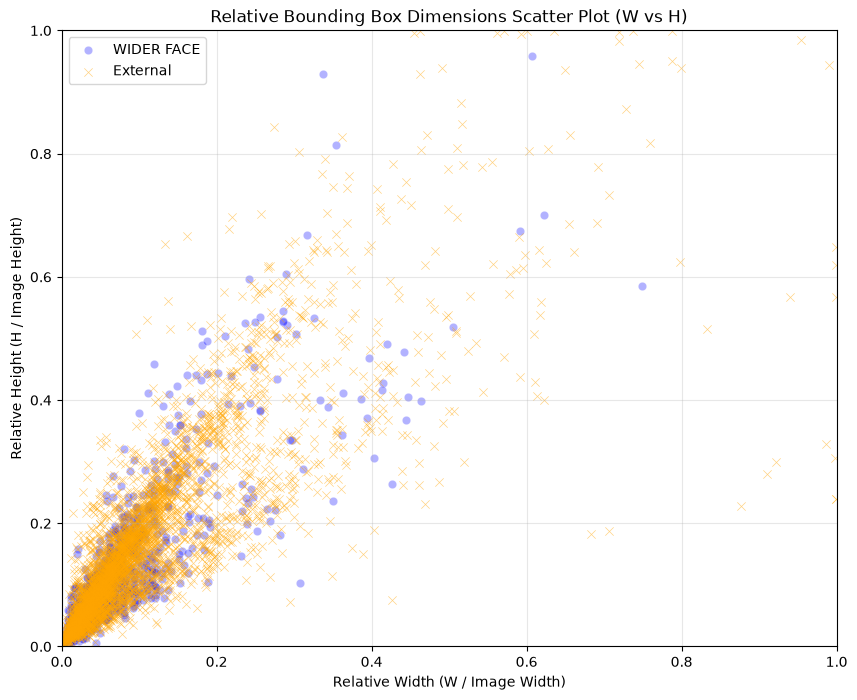

C:\Users\User\AppData\Local\Temp\ipykernel_24032\3912469166.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_faces, x="dataset", y="faces", palette="Set2")


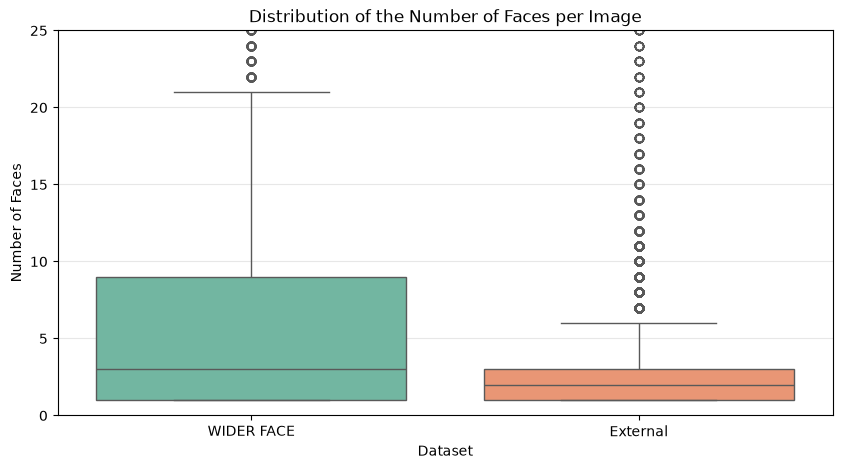

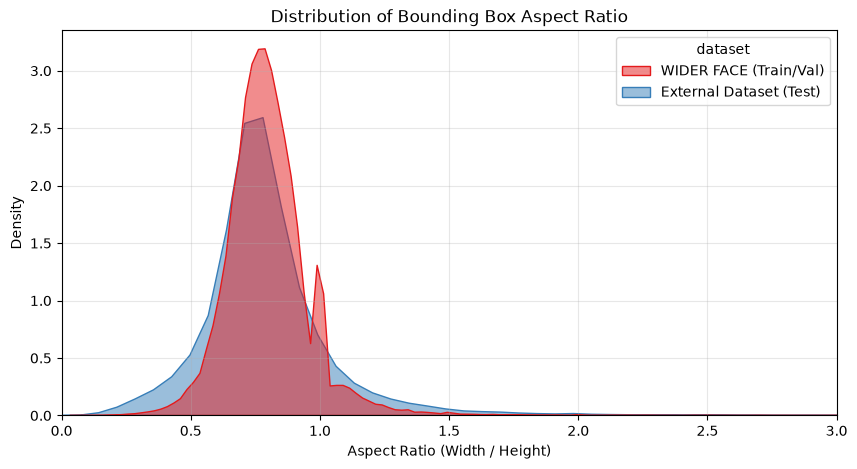

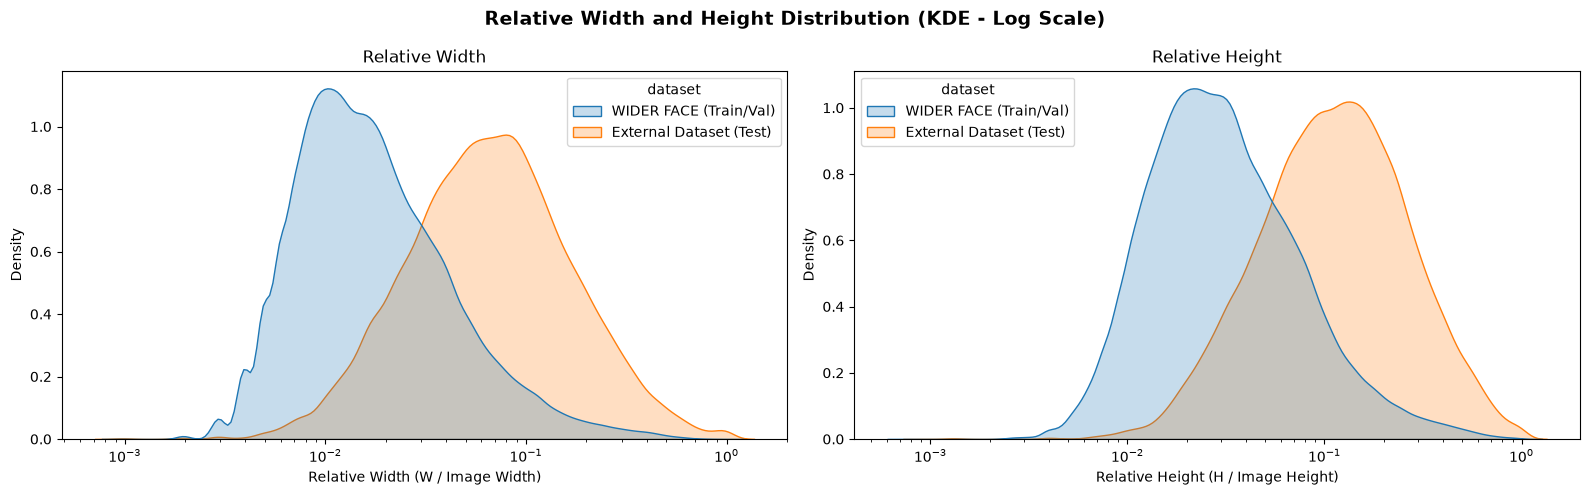

In [50]:
# Preparar DataFrames para comparação
df_wider = pd.DataFrame(train_boxes)
df_wider['dataset'] = 'WIDER FACE (Train/Val)'

df_ext = pd.DataFrame(ext_boxes)
df_ext['dataset'] = 'External Dataset (Test)'

df_combined = pd.concat([df_wider, df_ext], ignore_index=True)

# Gráfico 1: Distribuição da Área das Bounding Boxes (Escala Log)
plt.figure(figsize=(12, 6))
sns.histplot(data=df_combined, x="area", hue="dataset", bins=50, log_scale=True, 
             element="step", stat="density", common_norm=False, palette="Set1")
plt.title("Bounding Boxes Area Distribution (Log Scale)")
plt.xlabel("Area (pixels²)")
plt.ylabel("Density")
plt.legend(title="Dataset")
plt.grid(True, alpha=0.3)
plt.show()

# Gráfico 2: Dimensões Relativas (Largura vs Altura Relativas)
plt.figure(figsize=(10, 8))
sample_wider = df_wider.sample(min(5000, len(df_wider)))
sample_ext = df_ext.sample(min(5000, len(df_ext)))

sns.scatterplot(data=sample_wider, x="relative_w", y="relative_h", alpha=0.3, label="WIDER FACE", color="blue")
sns.scatterplot(data=sample_ext, x="relative_w", y="relative_h", alpha=0.5, label="External", color="orange", marker="x")

plt.title("Relative Bounding Box Dimensions Scatter Plot (W vs H)")
plt.xlabel("Relative Width (W / Image Width)")
plt.ylabel("Relative Height (H / Image Height)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Gráfico 3: Rostos por Imagem
faces_per_img_wider = pd.Series([len(r["boxes"]) for r in train_records], name="faces")
faces_per_img_wider = faces_per_img_wider[faces_per_img_wider > 0]

faces_per_img_ext = pd.Series([len(r["boxes"]) for r in ext_records_filtered], name="faces")

df_faces = pd.concat([
    faces_per_img_wider.to_frame().assign(dataset="WIDER FACE"),
    faces_per_img_ext.to_frame().assign(dataset="External")
], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_faces, x="dataset", y="faces", palette="Set2")
plt.title("Distribution of the Number of Faces per Image")
plt.ylabel("Number of Faces")
plt.xlabel("Dataset")
plt.ylim(0, 25)
plt.grid(True, alpha=0.3, axis='y')
plt.show()

# Calcular o Aspect Ratio (Largura / Altura)
df_combined['aspect_ratio'] = df_combined['w'] / df_combined['h']

# Gráfico 4: Distribuição da Proporção (Aspect Ratio)
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df_combined, x="aspect_ratio", hue="dataset", 
            common_norm=False, fill=True, palette="Set1", alpha=0.5)
plt.title("Distribution of Bounding Box Aspect Ratio")
plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Density")
plt.xlim(0, 3)
plt.grid(True, alpha=0.3)
plt.show()

# Gráfico 5: Densidade de Largura e Altura Relativas (Escala Log)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Relative Width and Height Distribution (KDE - Log Scale)", fontsize=14, weight="bold")

sns.kdeplot(data=df_combined, x="relative_w", hue="dataset", ax=axes[0], log_scale=True, fill=True, common_norm=False)
axes[0].set_title("Relative Width")
axes[0].set_xlabel("Relative Width (W / Image Width)")
axes[0].set_ylabel("Density")

sns.kdeplot(data=df_combined, x="relative_h", hue="dataset", ax=axes[1], log_scale=True, fill=True, common_norm=False)
axes[1].set_title("Relative Height")
axes[1].set_xlabel("Relative Height (H / Image Height)")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()